# 05: What do good T sides do that our bad ones don't?

**Question (mine):** compare how my team plays on T in the halves we lose badly vs how opponents play on their *successful* T halves (against us).
After a mid smoke, are they more decisive? Do they spam more smokes? Do they move faster somewhere?

**Groups** (regulation halves with 6+ rounds, same 64 demos):

- **our bad T**: we won ≤35% of the T rounds in that half
- **their good T**: the opponents won ≥60% of their T rounds against us
- **our good T**: we won ≥60%. This one's the reference: if our good halves look like theirs, the problem is what changes in our *bad* halves, not "they're just better".

**Economy trap:** our bad T halves have way more force buys (41% vs 16%). Being poor makes everything look worse, so the main comparison uses **full-buy rounds only**.

> 📝 = my own take.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
KEY = ["match_id", "round"]

quality = pd.read_parquet(P / "demo_quality.parquet")
OK = set(quality.loc[quality["ok"], "match_id"])
rf = pd.read_parquet(P / "round_features.parquet").query("match_id in @OK and not is_overtime")
kills = pd.read_parquet(P / "kills.parquet").query("match_id in @OK and not after_round_end")
nades = pd.read_parquet(P / "grenades.parquet").query("match_id in @OK and not after_round_end and type in ['smoke', 'flash', 'he', 'molotov']")
pos = pd.read_parquet(P / "positions.parquet").query("match_id in @OK")

plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
GROUP_COL = {"our bad T": "#e76f51", "our good T": "#2a9d8f", "their good T": "#e9c46a"}
GROUPS = list(GROUP_COL)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. The halves

In [2]:
h = rf.groupby(["match_id", "half", "my_side"]).agg(rounds=("round", "size"), our_wins=("my_team_won", "sum")).reset_index()
h["T_team"] = np.where(h["my_side"] == "T", "us", "them")
h["T_share"] = np.where(h["my_side"] == "T", h["our_wins"], h["rounds"] - h["our_wins"]) / h["rounds"]
h["group"] = np.select(
    [(h["T_team"] == "us") & (h["T_share"] <= 0.35), (h["T_team"] == "us") & (h["T_share"] >= 0.6),
     (h["T_team"] == "them") & (h["T_share"] >= 0.6)], GROUPS[0:1] + GROUPS[1:2] + GROUPS[2:3], "other")
h = h[(h["rounds"] >= 6) & (h["group"] != "other")]
h["half_id"] = h["match_id"] + "_" + h["half"].astype(str)

r = rf[~rf["is_pistol"]].merge(h[["match_id", "half", "group", "T_team", "half_id"]], on=["match_id", "half"])
r["T_won"] = np.where(r["T_team"] == "us", r["my_team_won"], ~r["my_team_won"].astype(bool))
r["T_buy"] = np.where(r["T_team"] == "us", r["my_team_buy"], r["enemy_buy"])
display(h.groupby("group").agg(halves=("rounds", "size"), rounds=("rounds", "sum"), T_round_win=("T_share", "mean")).round(2))
pd.crosstab(r["group"], r["T_buy"], normalize="index").round(2)

,halves,rounds,T_round_win
group,,,
our bad T,16,170,0.25
our good T,19,209,0.73
their good T,16,174,0.71


T_buy,eco,force,full
group,,,
our bad T,0.08,0.41,0.51
our good T,0.05,0.17,0.78
their good T,0.05,0.16,0.79


## 2. Tempo, positioning and utility of the T side, round by round

In [3]:
t_pos = pos[pos["side"] == "T"].merge(r[KEY + ["map"]], on=KEY).sort_values(KEY + ["steamid", "time_s"])
step = t_pos.groupby(KEY + ["steamid"])[["X", "Y"]].diff()
t_pos["speed"] = np.hypot(step["X"], step["Y"]) / 0.5                # units per second
t_pos.loc[t_pos["speed"] > 400, "speed"] = np.nan                     # respawn/teleport glitches
spawn = t_pos[t_pos["time_s"] < 1].groupby("map")[["X", "Y"]].median()
t_pos = t_pos.join(spawn.add_suffix("_spawn"), on="map")
t_pos["from_spawn"] = np.hypot(t_pos["X"] - t_pos["X_spawn"], t_pos["Y"] - t_pos["Y_spawn"])

f = r.set_index(KEY)[["map", "group", "half_id", "T_won", "T_buy", "bomb_planted"]].copy()
early = t_pos[(t_pos["time_s"] > 1) & (t_pos["time_s"] <= 40)]
f["speed_0_40s"] = early.groupby(KEY)["speed"].mean()
for t in (20, 30):
    a = t_pos[(t_pos["time_s"] >= t - 0.1) & (t_pos["time_s"] < t + 0.4)]
    f[f"distance_from_spawn_{t}s"] = a.groupby(KEY)["from_spawn"].mean()
    if t == 20:
        f["callouts_occupied_20s"] = a.groupby(KEY)["place"].nunique()
        f["biggest_stack_20s"] = a.groupby(KEY + ["place"]).size().groupby(level=[0, 1]).max()

opening = kills[kills["is_opening"]].groupby(KEY).agg(open_t=("time_s", "min"), T_won_opening=("attacker_side", lambda s: s.iloc[0] == "T"))
tn = nades[nades["thrower_side"] == "T"].join(opening, on=KEY)
tn = tn[tn.set_index(KEY).index.isin(f.index)]
pre = tn[tn["time_s"] < tn["open_t"].fillna(np.inf)]

def most_in_5s(t):
    t = np.sort(t.values); j = best = 0
    for i in range(len(t)):
        while t[i] - t[j] > 5:
            j += 1
        best = max(best, i - j + 1)
    return best

f["nades_before_first_kill"] = pre.groupby(KEY).size()
f["smokes_before_first_kill"] = pre[pre["type"] == "smoke"].groupby(KEY).size()
f["most_nades_within_5s"] = tn.groupby(KEY)["time_s"].apply(most_in_5s)
f["first_smoke_at_s"] = tn[tn["type"] == "smoke"].groupby(KEY)["time_s"].min()
f = f.join(opening)
f[["nades_before_first_kill", "smokes_before_first_kill", "most_nades_within_5s"]] = \
    f[["nades_before_first_kill", "smokes_before_first_kill", "most_nades_within_5s"]].fillna(0)
f = f.reset_index()

METRICS = ["T_won", "T_won_opening", "bomb_planted", "open_t", "speed_0_40s", "distance_from_spawn_20s",
           "distance_from_spawn_30s", "callouts_occupied_20s", "biggest_stack_20s",
           "nades_before_first_kill", "smokes_before_first_kill", "most_nades_within_5s", "first_smoke_at_s"]
full = f[f["T_buy"] == "full"]
display(full.groupby("group").size().rename("full-buy rounds"))
full.groupby("group")[METRICS].mean().T[GROUPS].round(2)

group
our bad T        78
our good T      148
their good T    125
Name: full-buy rounds, dtype: int64

group,our bad T,our good T,their good T
T_won,0.22,0.78,0.72
T_won_opening,0.42,0.58,0.59
bomb_planted,0.37,0.75,0.55
open_t,19.65,17.58,17.29
speed_0_40s,138.08,140.40,139.33
distance_from_spawn_20s,1815.69,1984.56,1923.58
distance_from_spawn_30s,2110.26,2298.08,2256.25
callouts_occupied_20s,2.78,3.07,3.18
biggest_stack_20s,2.42,2.21,1.96
nades_before_first_kill,2.56,3.11,3.58


In [4]:
# our bad T minus their good T, 95% interval by resampling whole halves
rng = np.random.default_rng(0)

def boot(d, col, n=2000):
    a = d[d["group"] == "our bad T"].groupby("half_id")[col].agg(["sum", "count"])
    b = d[d["group"] == "their good T"].groupby("half_id")[col].agg(["sum", "count"])
    out = []
    for _ in range(n):
        ra, rb = a.iloc[rng.integers(0, len(a), len(a))].sum(), b.iloc[rng.integers(0, len(b), len(b))].sum()
        out.append(ra["sum"] / ra["count"] - rb["sum"] / rb["count"])
    return np.percentile(out, [2.5, 97.5])

rows = []
for col in METRICS[3:]:
    d = full.dropna(subset=[col])
    lo, hi = boot(d, col)
    rows.append(dict(metric=col, our_bad_T=d.loc[d["group"] == "our bad T", col].mean(),
                     their_good_T=d.loc[d["group"] == "their good T", col].mean(), ci_low=lo, ci_high=hi))
diff = pd.DataFrame(rows).set_index("metric")
diff["difference"] = diff["our_bad_T"] - diff["their_good_T"]
diff["clear?"] = np.where((diff["ci_high"] < 0) | (diff["ci_low"] > 0), "yes", "")
diff[["our_bad_T", "their_good_T", "difference", "ci_low", "ci_high", "clear?"]].round(2)

,our_bad_T,their_good_T,difference,ci_low,ci_high,clear?
metric,,,,,,
open_t,19.65,17.29,2.36,-1.75,6.72,
speed_0_40s,138.08,139.33,-1.25,-9.78,6.69,
distance_from_spawn_20s,1815.69,1923.58,-107.89,-300.70,65.16,
distance_from_spawn_30s,2110.26,2256.25,-145.99,-382.01,67.69,
callouts_occupied_20s,2.78,3.18,-0.40,-0.66,-0.13,yes
biggest_stack_20s,2.42,1.96,0.46,0.19,0.73,yes
nades_before_first_kill,2.56,3.58,-1.02,-2.20,0.14,
smokes_before_first_kill,0.79,1.24,-0.45,-0.90,0.01,
most_nades_within_5s,2.58,3.66,-1.08,-1.52,-0.57,yes


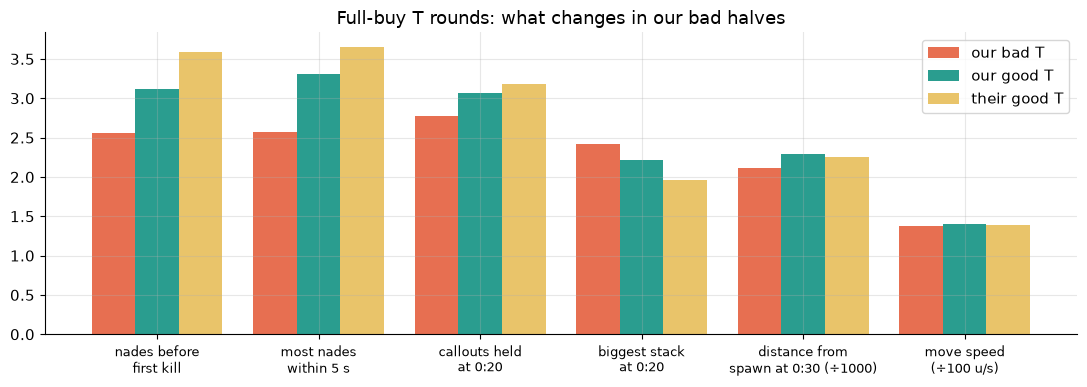

In [5]:
show = {"nades_before_first_kill": "nades before\nfirst kill", "most_nades_within_5s": "most nades\nwithin 5 s",
        "callouts_occupied_20s": "callouts held\nat 0:20", "biggest_stack_20s": "biggest stack\nat 0:20",
        "distance_from_spawn_30s": "distance from\nspawn at 0:30 (÷1000)", "speed_0_40s": "move speed\n(÷100 u/s)"}
m = full.groupby("group")[list(show)].mean().T[GROUPS]
m.loc["distance_from_spawn_30s"] /= 1000
m.loc["speed_0_40s"] /= 100
x = np.arange(len(show))
fig, ax = plt.subplots(figsize=(11, 4))
for i, g in enumerate(GROUPS):
    ax.bar(x + (i - 1) * 0.27, m[g], width=0.27, color=GROUP_COL[g], label=g)
ax.set_xticks(x, list(show.values()), fontsize=9)
ax.set_title("Full-buy T rounds: what changes in our bad halves")
ax.legend()
save("05_t_side_profile")

**Movement speed is identical** (~140 units/s for everyone). Nobody's simply running faster.

Three differences are **clear** (the interval excludes zero, resampling whole halves):

- **We clump.** At 0:20 their good T sides cover **more callouts** (3.2 vs 2.8) with **smaller stacks**. In our bad halves the biggest stack is ~2.4 players vs ~2.0.
- **Our nades don't come together.** The most we throw within any 5 seconds is ~2.6 vs ~3.7. Good T sides **bundle** utility, which is what an execute is.

And three point the same way but **aren't clear** with 16 halves a side:

- ~1 fewer nade before the first kill (2.6 vs 3.6) and fewer smokes (0.8 vs 1.2).
- Less ground taken by 0:30 (~150 units closer to spawn on average).
- First smoke ~2 s later.

Plus the one we already knew: we win the **opening duel** only 42% in bad halves vs 59%.

Our **good** T halves sit in between on most of these: a bit closer to their good halves on spread and map control, but still lighter on utility.

## 3. After the mid smoke: more decisive?

In [6]:
# name smoke landing spots by nearest callout
pl = pos[pos["place"] != ""].merge(rf[["match_id", "map"]].drop_duplicates(), on="match_id")
sm = nades[(nades["type"] == "smoke") & (nades["thrower_side"] == "T")].merge(f[KEY + ["map", "group", "T_buy", "T_won"]], on=KEY)
sm["land_place"] = ""
for mp, sub in sm.groupby("map"):
    pp = pl[pl["map"] == mp]
    pp = pp.sample(min(len(pp), 150_000), random_state=0)
    _, i = cKDTree(pp[["X", "Y", "Z"]].values).query(sub[["land_X", "land_Y", "land_Z"]].values)
    sm.loc[sub.index, "land_place"] = pp["place"].values[i]

MID_SMOKE = {"de_mirage": {"SnipersNest", "TopofMid", "Middle", "Connector", "Catwalk", "Jungle"},
             "de_inferno": {"Middle", "TopofMid", "SecondMid", "Arch", "Library"},
             "de_dust2": {"Middle", "MidDoors", "TopofMid", "Catwalk", "ShortStairs", "CTSpawn"}}
MID_ZONE = {"de_mirage": {"Middle", "TopofMid", "Catwalk", "Connector", "Underpass", "SnipersNest", "Jungle"},
            "de_inferno": {"Middle", "TopofMid", "SecondMid", "LowerMid", "Arch"},
            "de_dust2": {"Middle", "MidDoors", "TopofMid", "Catwalk", "ShortStairs", "LowerTunnel"}}
sm = sm[sm["map"].isin(MID_SMOKE)]
sm["is_mid"] = [p in MID_SMOKE[m] for p, m in zip(sm["land_place"], sm["map"])]
first_mid = (sm[sm["is_mid"] & (sm["time_s"] < 40)].sort_values("time_s")
             .groupby(KEY).agg(mid_smoke_at=("time_s", "first"), mid_smokes=("time_s", "size"), first_mid_smoke=("land_place", "first")))

three = f[f["map"].isin(MID_SMOKE)].set_index(KEY).join(first_mid)
three["smoked_mid"] = three["mid_smoke_at"].notna()
display(three.groupby("group").agg(T_rounds=("T_won", "size"), smoked_mid_by_0_40=("smoked_mid", "mean"),
        mid_smokes_when_they_do=("mid_smokes", "mean"), first_mid_smoke_at_s=("mid_smoke_at", "median")).loc[GROUPS].round(2))

ms = three[three["smoked_mid"]].reset_index()
tp = t_pos[t_pos["map"].isin(MID_ZONE)].copy()
tp["in_mid"] = [p in MID_ZONE[m] for p, m in zip(tp["place"], tp["map"])]
tp = tp.merge(ms[KEY + ["mid_smoke_at"]], on=KEY)
for dt in (0, 5, 10):
    a = tp[(tp["time_s"] >= tp["mid_smoke_at"] + dt - 0.25) & (tp["time_s"] < tp["mid_smoke_at"] + dt + 0.25)]
    ms = ms.join(a.groupby(KEY)["in_mid"].sum().rename(f"T_in_mid_{dt}s_after"), on=KEY)
kk = kills.merge(ms[KEY + ["mid_smoke_at"]], on=KEY)
w = kk[(kk["time_s"] >= kk["mid_smoke_at"]) & (kk["time_s"] < kk["mid_smoke_at"] + 10)]
ms = ms.join(w[w["attacker_side"] == "T"].groupby(KEY).size().rename("T_kills_next_10s"), on=KEY)
ms = ms.join(w[w["victim_side"] == "T"].groupby(KEY).size().rename("T_deaths_next_10s"), on=KEY)
ms[["T_kills_next_10s", "T_deaths_next_10s"]] = ms[["T_kills_next_10s", "T_deaths_next_10s"]].fillna(0)
nxt = kk[kk["time_s"] >= kk["mid_smoke_at"]].sort_values("time_s").groupby(KEY)["time_s"].first()
ms = ms.join((nxt.rename("t") - ms.set_index(KEY)["mid_smoke_at"]).rename("secs_to_next_kill"), on=KEY)
ms.groupby("group")[["T_in_mid_0s_after", "T_in_mid_5s_after", "T_in_mid_10s_after", "T_kills_next_10s",
                     "T_deaths_next_10s", "secs_to_next_kill", "T_won"]].mean().loc[GROUPS].round(2)

,T_rounds,smoked_mid_by_0_40,mid_smokes_when_they_do,first_mid_smoke_at_s
group,,,,
our bad T,105,0.57,1.32,11.36
our good T,168,0.57,1.62,10.00
their good T,136,0.70,1.94,8.31


,T_in_mid_0s_after,T_in_mid_5s_after,T_in_mid_10s_after,T_kills_next_10s,T_deaths_next_10s,secs_to_next_kill,T_won
group,,,,,,,
our bad T,1.60,2.23,2.02,0.58,0.72,12.06,0.33
our good T,1.48,2.14,1.97,0.58,0.60,9.34,0.76
their good T,1.38,2.13,2.09,0.75,0.51,8.15,0.75


In [7]:
mir = ms[ms["map"] == "de_mirage"]
mir.groupby("group")["first_mid_smoke"].value_counts(normalize=True).groupby(level=0).head(3).round(2).rename("share of first mid smokes").to_frame()

share of first mid smokes
group        first_mid_smoke                           
our bad T    SnipersNest                           0.87
             Middle                                0.10
             Jungle                                0.03
our good T   SnipersNest                           0.58
             Middle                                0.15
             Catwalk                               0.14
their good T SnipersNest                           0.62
             Middle                                0.21
             Catwalk                               0.10

In [8]:
ms["net_kills_next_10s"] = ms["T_kills_next_10s"] - ms["T_deaths_next_10s"]
lo, hi = boot(ms, "net_kills_next_10s")
print(f"net kills in the 10 s after the mid smoke, our bad T minus their good T: "
      f"{ms.loc[ms['group'] == 'our bad T', 'net_kills_next_10s'].mean() - ms.loc[ms['group'] == 'their good T', 'net_kills_next_10s'].mean():.2f} "
      f"(95% interval {lo:.2f} to {hi:.2f})")
lo, hi = boot(ms, "mid_smokes")
print(f"mid smokes per round: difference interval {lo:.2f} to {hi:.2f}")

net kills in the 10 s after the mid smoke, our bad T minus their good T: -0.38 (95% interval -0.72 to -0.04)


mid smokes per round: difference interval -0.92 to -0.27


**Not more decisive in the sense of moving faster.** About the same number of players walk into mid in the 5–10 s after the smoke (~2.1–2.2) for every group.

What's different:

- **They smoke mid more often and earlier**: 70% of their good T rounds vs 57% of ours, first mid smoke at ~0:08 vs ~0:11.
- **They do spam more**: ~1.9 mid smokes per round when they smoke mid, vs ~1.3 in our bad halves. On Mirage, **87%** of our first mid smokes in bad halves go to Window. Their good T sides start with Window only 62% of the time and mix in Middle / Catwalk smokes, i.e. they **cut mid into pieces** instead of blocking one angle.
- **They win the fights right after it**: in the 10 s after the mid smoke they get **0.75 kills for 0.51 deaths**. In our bad halves it's **0.58 kills for 0.72 deaths**. Same number of players in mid, opposite result.

So "decisive" here isn't speed. It's **more smoke cover, earlier, and then winning the fight it sets up**. That fits notebook 02 (our Window smoke alone barely helped) and notebook 03 (their Window smoke on us cost us ~14 points).

## 4. On the map: Mirage at 0:20

zone,A side,B side,T spawn,mid,other
group,,,,,
our bad T,0.38,0.02,0.05,0.40,0.15
our good T,0.31,0.10,0.03,0.42,0.13
their good T,0.39,0.06,0.03,0.45,0.06


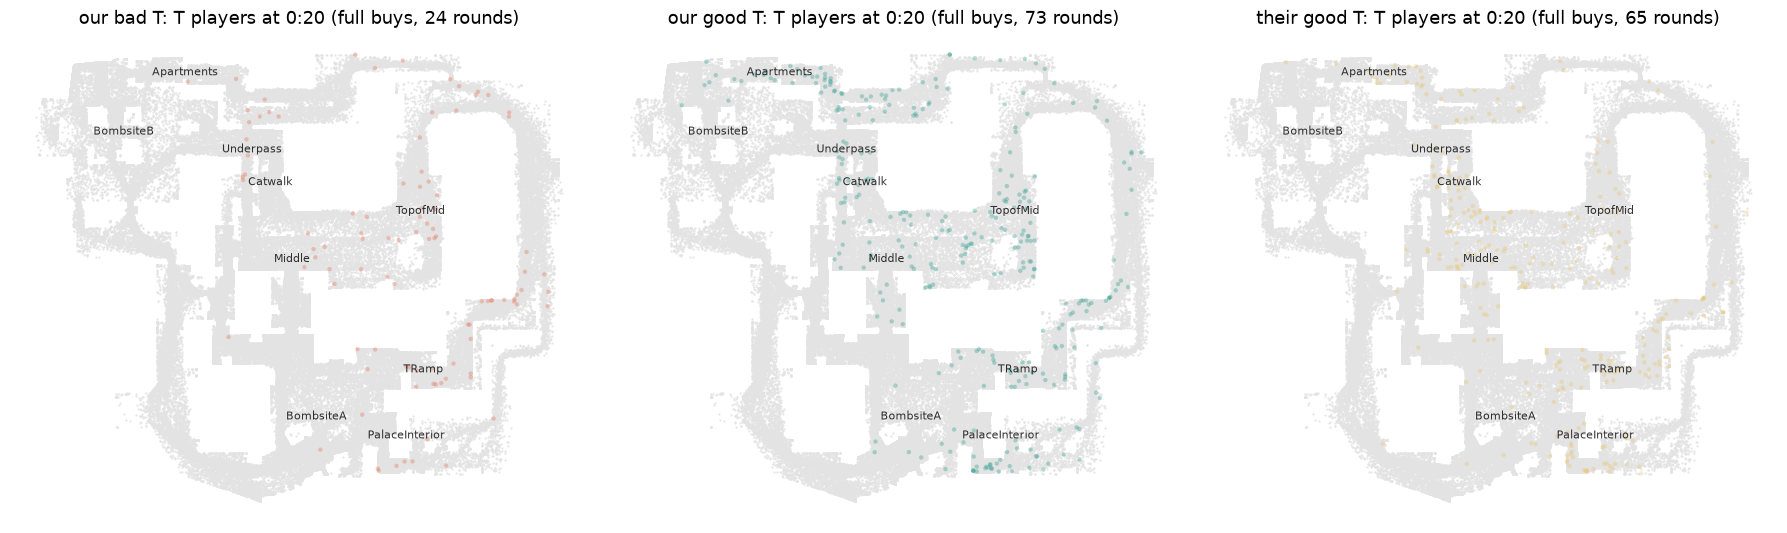

In [9]:
mir_ids = rf.loc[rf["map"] == "de_mirage", "match_id"].unique()
bg = pos[pos["match_id"].isin(mir_ids)].sample(120_000, random_state=1)
labels_xy = bg[bg["place"] != ""].groupby("place")[["X", "Y"]].median()
snap = t_pos[(t_pos["map"] == "de_mirage") & (t_pos["time_s"] >= 19.9) & (t_pos["time_s"] < 20.4)].merge(
    f[KEY + ["group", "T_buy"]], on=KEY)
snap = snap[snap["T_buy"] == "full"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, g in zip(axes, GROUPS):
    ax.scatter(bg["X"], bg["Y"], s=0.3, color="#e3e3e3", rasterized=True)
    s = snap[snap["group"] == g]
    ax.scatter(s["X"], s["Y"], s=10, color=GROUP_COL[g], alpha=0.35, edgecolor="none")
    for place in ["TopofMid", "Middle", "PalaceInterior", "TRamp", "Apartments", "BombsiteA", "BombsiteB", "Underpass", "Catwalk"]:
        if place in labels_xy.index:
            ax.text(*labels_xy.loc[place], place, fontsize=8, ha="center", alpha=0.8)
    ax.set_title(f"{g}: T players at 0:20 (full buys, {s.groupby(KEY).ngroups} rounds)")
    ax.set_aspect("equal"); ax.axis("off")
save("05_mirage_t_at_20s")

snap["zone"] = np.select([snap["place"].isin(["Middle", "TopofMid", "Catwalk", "Connector", "Underpass", "SnipersNest"]),
                          snap["place"].isin(["Apartments", "BombsiteB", "Shop", "Truck"]),
                          snap["place"].isin(["TRamp", "PalaceInterior", "PalaceAlley", "BombsiteA"]),
                          snap["place"].isin(["TSpawn"])], ["mid", "B side", "A side", "T spawn"], "other")
pd.crosstab(snap["group"], snap["zone"], normalize="index").loc[GROUPS].round(2)

Where the T side stands at 0:20 on Mirage (full buys). Only 24 of our bad-half rounds are Mirage full buys, so this is a rough picture.

The mid/A split is about the same for everyone (~40% mid, ~38% A side). Two differences:
- **B side is empty in our bad halves** (2% of players vs 6–10%). Nobody's showing B, so the CTs can stack mid and A.
- **15% of our players are "in between"** (T-side connectors, not yet anywhere) vs 6% for their good T sides. Same idea as the clumping: we're slower to *spread out*, not slower to *move*.

> 📝 **My take:** (react to this)

## 5. Which of these actually *cause* good T rounds? A within-match check

Everything above compares halves that were **picked by their result**, so some of it may be a *consequence* of losing rounds rather than a cause.
Two fixes:

1. **Measure only before the first kill.** Formation (callouts covered, biggest stack) at the last moment before anyone dies, and utility thrown before the first kill. Then nothing in the measurement can be a result of a kill.
2. **Compare rounds within the same match**, same T team: same opponents, same map, same night. Each team-in-a-match gets its own baseline (a "fixed effect"), and the money difference is controlled for.

All 1,194 regulation gun rounds (no overtime), both teams on T (us and them). The 95% intervals come from resampling whole matches.

In [10]:
r5 = rf[~rf["is_pistol"]][KEY + ["map", "my_side", "my_team_won", "equip_diff"]].copy()
r5["T_team"] = np.where(r5["my_side"] == "T", "us", "them")
r5["T_won"] = np.where(r5["T_team"] == "us", r5["my_team_won"], ~r5["my_team_won"].astype(bool)).astype(int)
r5["T_money_adv_k"] = np.where(r5["T_team"] == "us", r5["equip_diff"], -r5["equip_diff"]) / 1000
op5 = kills[kills["is_opening"]].groupby(KEY).agg(open_t=("time_s", "min"), open_tick=("tick", "min"),
                                                  T_won_opening=("attacker_side", lambda s: int(s.iloc[0] == "T")))
r5 = r5.join(op5, on=KEY)
r5["grp"] = r5["match_id"] + "_" + r5["T_team"]

# formation at the last position sample before the first kill
tp5 = pos[pos["side"] == "T"].join(op5, on=KEY)
tp5 = tp5[tp5["time_s"] < tp5["open_t"].fillna(np.inf) - 0.25]
tp5 = tp5[tp5["time_s"] == tp5.groupby(KEY)["time_s"].transform("max")]
r5 = r5.join(tp5.groupby(KEY)["place"].nunique().rename("callouts_pre"), on=KEY)
r5 = r5.join(tp5.groupby(KEY + ["place"]).size().groupby(level=[0, 1]).max().rename("biggest_stack_pre"), on=KEY)

# utility before the first kill
tn5 = nades[nades["thrower_side"] == "T"].join(op5, on=KEY)
tn5 = tn5[tn5["tick"] < tn5["open_tick"].fillna(np.inf)]
r5 = r5.join(tn5.groupby(KEY).size().rename("nades_pre"), on=KEY)
r5 = r5.join(tn5.groupby(KEY)["time_s"].apply(most_in_5s).rename("most_nades_in_5s_pre"), on=KEY)

# mid smokes before the first kill (Mirage, Inferno, Dust2)
s5 = tn5[tn5["type"] == "smoke"].merge(rf[["match_id", "map"]].drop_duplicates(), on="match_id")
s5 = s5[s5["map"].isin(MID_SMOKE)].copy()
s5["land_place"] = ""
for mp, sub in s5.groupby("map"):
    pp = pl[pl["map"] == mp]
    pp = pp.sample(min(len(pp), 150_000), random_state=0)
    _, i = cKDTree(pp[["X", "Y", "Z"]].values).query(sub[["land_X", "land_Y", "land_Z"]].values)
    s5.loc[sub.index, "land_place"] = pp["place"].values[i]
s5 = s5[[lp in MID_SMOKE[m] for lp, m in zip(s5["land_place"], s5["map"])]]
r5 = r5.join(s5.groupby(KEY).size().rename("mid_smokes_pre"), on=KEY)
r5[["nades_pre", "most_nades_in_5s_pre"]] = r5[["nades_pre", "most_nades_in_5s_pre"]].fillna(0)
three5 = r5["map"].isin(MID_SMOKE)
r5.loc[three5, "mid_smokes_pre"] = r5.loc[three5, "mid_smokes_pre"].fillna(0)
r5["two_plus_mid_smokes"] = np.where(three5, (r5["mid_smokes_pre"] >= 2).astype(float), np.nan)

def within_match(d, y, x, n_boot=500):
    # linear probability model, one fixed effect per (match, T team), money control; bootstrap over matches
    def fit(dd):
        cols = [y, x, "T_money_adv_k"]
        D = dd[cols + ["grp"]].dropna()
        D[cols] = D[cols] - D.groupby("grp")[cols].transform("mean")
        return np.linalg.lstsq(D[[x, "T_money_adv_k"]].values, D[y].values, rcond=None)[0][0]
    b = fit(d)
    ids = d["match_id"].unique()
    by_match = {m: g for m, g in d.groupby("match_id")}
    boots = []
    for _ in range(n_boot):
        pick = rng.choice(ids, len(ids))
        boots.append(fit(pd.concat([by_match[m].assign(grp=by_match[m]["grp"] + f"_{i}") for i, m in enumerate(pick)])))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return b, lo, hi

rows = []
for x in ["callouts_pre", "biggest_stack_pre", "nades_pre", "most_nades_in_5s_pre", "mid_smokes_pre", "two_plus_mid_smokes"]:
    for y in ["T_won", "T_won_opening"]:
        b, lo, hi = within_match(r5.dropna(subset=[x]), y, x)
        rows.append(dict(measured_before_first_kill=x, outcome=y, effect=b, ci_low=lo, ci_high=hi))
wm = pd.DataFrame(rows)
wm["clear?"] = np.where((wm["ci_low"] > 0) | (wm["ci_high"] < 0), "yes", "")
wm.round(3)

,measured_before_first_kill,outcome,effect,ci_low,ci_high,clear?
0,callouts_pre,T_won,0.012,-0.016,0.041,
1,callouts_pre,T_won_opening,0.000,-0.032,0.031,
2,biggest_stack_pre,T_won,-0.002,-0.031,0.027,
3,biggest_stack_pre,T_won_opening,-0.000,-0.026,0.029,
4,nades_pre,T_won,-0.003,-0.017,0.009,
5,nades_pre,T_won_opening,-0.004,-0.017,0.010,
6,most_nades_in_5s_pre,T_won,-0.008,-0.027,0.011,
7,most_nades_in_5s_pre,T_won_opening,-0.009,-0.029,0.013,
8,mid_smokes_pre,T_won,0.019,-0.021,0.058,
9,mid_smokes_pre,T_won_opening,0.030,-0.015,0.072,


`effect` = change in the chance of winning per one more unit (one more callout, one more nade...), compared with other rounds of the **same team in the same match**.

**Almost everything disappears.** Measured before the first kill, spreading out, stack size, number of nades and bundling have **no clear link** to winning the round or the opening duel.

So why did the earlier sections find them? Because they were measured at **0:20 / over the whole round**, *after* kills had often already happened:

In [11]:
a20 = pos[(pos["side"] == "T") & (pos["time_s"] >= 19.9) & (pos["time_s"] < 20.4)]
r5 = r5.join(a20.groupby(KEY)["place"].nunique().rename("callouts_at_20s"), on=KEY)
rows = []
for label, d in [("a kill already happened before 0:20", r5[r5["open_t"] < 20]), ("nobody dead yet at 0:20", r5[r5["open_t"] >= 20])]:
    b, lo, hi = within_match(d, "T_won", "callouts_at_20s")
    rows.append(dict(rounds=label, n=len(d), effect_per_callout=b, ci_low=lo, ci_high=hi))
pd.DataFrame(rows).round(3)

,rounds,n,effect_per_callout,ci_low,ci_high
0,a kill already happened before 0:20,884,0.118,0.088,0.146
1,nobody dead yet at 0:20,310,-0.002,-0.067,0.074


That's the giveaway. "Callouts covered at 0:20" predicts winning **only when someone has already died**: fewer players alive = fewer callouts covered. When nobody's dead yet, it predicts nothing.
**The clumping and the scattered nades in our bad halves are mostly what losing the first fight looks like, not why we lose it.** Good to know before building habits around them.

### The one that survives (sort of): two mid smokes

In [12]:
m5 = r5[three5].copy()
m5["mid_smokes"] = m5["mid_smokes_pre"].clip(upper=2).astype(int).map({0: "0", 1: "1", 2: "2+"})
for col in ["T_won", "T_won_opening"]:
    m5[col + "_vs_same_match"] = m5[col] - m5.groupby("grp")[col].transform("mean")
display(m5.groupby("mid_smokes").agg(rounds=("T_won", "size"), round_win=("T_won", "mean"),
        round_win_vs_same_match=("T_won_vs_same_match", "mean"), opening_vs_same_match=("T_won_opening_vs_same_match", "mean")).round(3))
display(m5.groupby(["map", "mid_smokes"]).agg(rounds=("T_won", "size"), round_win_vs_same_match=("T_won_vs_same_match", "mean")).unstack().round(3))
m5.groupby(["T_team", "mid_smokes"])["T_won_vs_same_match"].mean().unstack().round(3)

,rounds,round_win,round_win_vs_same_match,opening_vs_same_match
mid_smokes,,,,
0,584,0.466,-0.020,-0.015
1,308,0.481,-0.001,-0.018
2+,148,0.595,0.081,0.096


rounds           round_win_vs_same_match              
mid_smokes      0    1   2+                       0      1     2+
map                                                              
de_dust2      135   62   12                  -0.011 -0.002  0.132
de_inferno    186   57   11                  -0.001  0.000  0.016
de_mirage     263  189  125                  -0.038 -0.001  0.082

mid_smokes,0,1,2+
T_team,,,
them,-0.039,0.015,0.084
us,-0.004,-0.020,0.076


- **One mid smoke does nothing.** Rounds with exactly one are no better than rounds with none, within the same match.
- **Two or more** before the first kill: about **+10 points** on the opening duel (the interval clears zero) and about **+6–7 points** on the round (the interval just touches zero).
- It points the same way **for both teams** (us and our opponents) and on all three maps. But **Inferno and Dust2 only have ~11–12 such rounds each**, so in practice this is a **Mirage** finding (125 of the 148 rounds).

**Honest caveats:**
- I picked the "2+" cut-off *after* seeing the 0/1/2+ table. Looking at the data and then choosing the split is exactly how false findings get made, so this is a **hypothesis, not a result**.
- Teams may throw two mid smokes in rounds where they were going to play well anyway (a set play, a confident round). The within-match comparison doesn't remove that.

The way to settle it is the coin-flip test: on Mirage T full buys, flip before the round. Heads = two mid smokes together, tails = play normally. That would be a separate experiment, after the current one finishes.

### Follow-up questions (mine)

1. *Does this assume 2+ of us actually go mid after the smokes?*
2. *When the smokes go in and we get the opening kill, where does the kill come from?*
3. *Is this my team, or every T side?*
4. *Which spots are the 2+ smokes, per map?*

In [13]:
# 3. who: every T side in these demos (us AND opponents), all rounds, not just the good/bad halves
m5["two_plus"] = m5["mid_smokes"] == "2+"
display(m5.groupby("T_team").agg(T_rounds=("T_won", "size"), rounds_with_2plus_mid_smokes=("two_plus", "sum"),
                                 share=("two_plus", "mean")).round(3))

# 4. which smokes: the set of mid spots smoked before the first kill, in 2+ rounds
combo = s5.sort_values("time_s").groupby(KEY)["land_place"].apply(lambda s: " + ".join(sorted(set(s)))).rename("mid_smokes_landed_at")
two = m5[m5["two_plus"]].join(combo, on=KEY)
for mp in ["de_mirage", "de_inferno", "de_dust2"]:
    d = two[two["map"] == mp]
    print(f"{mp} ({len(d)} rounds):", d["mid_smokes_landed_at"].value_counts().head(4).to_dict())

,T_rounds,rounds_with_2plus_mid_smokes,share
T_team,,,
them,531,96,0.181
us,509,52,0.102


de_mirage (125 rounds): {'Middle + SnipersNest': 42, 'Connector + SnipersNest': 35, 'Catwalk + SnipersNest': 13, 'SnipersNest': 7}
de_inferno (11 rounds): {'TopofMid': 7, 'Middle + TopofMid': 3, 'Middle': 1}
de_dust2 (12 rounds): {'MidDoors': 4, 'MidDoors + Middle': 3, 'Catwalk + MidDoors': 2, 'Middle': 1}


In [14]:
# 1. how many T players are in mid at the last moment before the first kill?
MID_AREA = MID_ZONE
pre5 = tp5.merge(rf[["match_id", "map"]].drop_duplicates(), on="match_id")
pre5 = pre5[pre5["map"].isin(MID_AREA)]
pre5["in_mid"] = [p in MID_AREA[m] for p, m in zip(pre5["place"], pre5["map"])]
m5 = m5.join(pre5.groupby(KEY)["in_mid"].sum().rename("T_in_mid_before_first_kill"), on=KEY)
m5["two_plus_in_mid"] = m5["T_in_mid_before_first_kill"] >= 2
display(m5.groupby("mid_smokes").agg(T_in_mid=("T_in_mid_before_first_kill", "mean"), share_with_2plus_in_mid=("two_plus_in_mid", "mean"),
                                     first_kill_at_s=("open_t", "median")).round(2))
m5[m5["two_plus"]].groupby("two_plus_in_mid").agg(rounds=("T_won", "size"), won_opening=("T_won_opening", "mean"), won_round=("T_won", "mean")).round(2)

,T_in_mid,share_with_2plus_in_mid,first_kill_at_s
mid_smokes,,,
0,1.17,0.34,12.94
1,1.92,0.57,16.23
2+,2.57,0.77,17.88


,rounds,won_opening,won_round
two_plus_in_mid,,,
False,34,0.56,0.53
True,114,0.62,0.61


In [15]:
# 2. Mirage: where does the T opening kill come from?
first_kill = kills[kills["is_opening"]].sort_values("tick").groupby(KEY).first()[["attacker_last_place_name", "victim_last_place_name"]]
mk = m5[(m5["map"] == "de_mirage") & (m5["T_won_opening"] == 1)].join(first_kill, on=KEY)
AREA = {**dict.fromkeys(["TopofMid", "Middle", "Catwalk", "Connector", "Underpass"], "mid"),
        **dict.fromkeys(["PalaceInterior", "PalaceAlley", "TRamp", "BombsiteA", "Scaffolding", "Stairs", "Jungle"], "A side"),
        **dict.fromkeys(["Apartments", "BombsiteB", "Truck", "Shop"], "B side")}
mk["killer_area"] = mk["attacker_last_place_name"].map(AREA).fillna("other")
display(pd.crosstab(mk["mid_smokes"].replace({"0": "0–1", "1": "0–1"}), mk["killer_area"], normalize="index").round(2))
mk2 = mk[mk["two_plus"]]
pd.concat({"killer stood at": mk2["attacker_last_place_name"].value_counts(normalize=True).head(5),
           "CT victim was at": mk2["victim_last_place_name"].value_counts(normalize=True).head(5)}, axis=1).round(2)

killer_area,A side,B side,mid,other
mid_smokes,,,,
0–1,0.45,0.05,0.46,0.04
2+,0.31,0.03,0.58,0.08


,killer stood at,CT victim was at
TopofMid,0.22,NaN
Catwalk,0.19,NaN
PalaceInterior,0.14,0.16
Middle,0.12,0.21
PalaceAlley,0.09,NaN
BombsiteA,NaN,0.09
Underpass,NaN,0.08
Connector,NaN,0.08


1. **No, the analysis doesn't assume anyone goes mid.** But in practice they mostly do: in 2+ smoke rounds, **77%** have 2+ T players in mid right before the first kill (vs 34% with no mid smoke). Rounds where the smokes went in but fewer than 2 went mid did a bit worse (n=34, so rough). The smokes also **slow the first fight down** (median first kill ~0:18 vs ~0:13), so they're buying time to walk in, not rushing.
2. **On Mirage, the kill comes from mid.** With 2+ smokes, 58% of T opening kills come from mid (Top of Mid, Catwalk, Middle) vs 46% otherwise, and fewer from Palace/A. The CT who dies first is most often the **mid player (Middle, 21%)** or the Palace holder. So the second smoke seems to let the T side win the *mid* fight, which is exactly the fight we lose (notebook 02: Top of Mid first deaths).
3. **Every T side in our 64 demos**, us and opponents, all rounds. Opponents do it in **18%** of their T rounds, **we do it in 10%**. The effect is about the same for both teams.
4. **Mirage:** Window + Middle (42 rounds) and Window + Connector (35) are the big two, then Window + Catwalk (13). **Inferno:** Top of Mid (often two smokes there) or Top of Mid + Middle. **Dust2:** Mid Doors, sometimes + Middle or Catwalk. Inferno and Dust2 are ~11–12 rounds each, so only Mirage is worth acting on.

**If we test it, the Mirage version is:** Window + Connector (or Window + Middle) together, then 2 players take mid.

## Summary

**What looked different** in our bad T halves vs the opponents' good T halves (full buys): same movement speed, but we clumped, our nades didn't come together, we smoked mid less, and we lost the fights after the mid smoke.

**What survived the within-match check** (measured before the first kill, same team in the same match):

1. **Clumping, spread and bundled nades: no.** They mostly show up *after* we've already lost a player. They're what losing the first fight looks like, not the reason.
2. **Number of nades before the first kill: no clear link** within a match either. (H2 in the experiment still gets tested properly, which is the point of running it.)
3. **Two or more mid smokes before the first kill: maybe.** +10 points on the opening duel, +6–7 on the round, for both teams. In practice it's a Mirage finding (Window + Connector / Window + Middle, then 2 players take mid; the opening kill then comes from mid). We do it in 10% of T rounds, opponents in 18%. The cut-off was chosen after looking, so it needs its own test.

**Lesson for me:** a pattern in "bad halves vs good halves" can be pure consequence. Measuring before the event and comparing within the same match removed most of what looked like a story.

> 📝 **My take, in my own words:** (3–5 bullets)